In [2]:
%matplotlib inline
import slmsuite
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib as mpl
from slmsuite.holography import toolbox
from slmsuite.holography.toolbox import phase
from matplotlib import pyplot as plt
mpl.rc('image', cmap='Blues')


In [307]:
#Create a virtual SLM and camera
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
wav_um = 1.064
slm_shape = (1024, 1280) # (give height, width)
cam_shape = (1080,1440) # (give height, width)
slm = SimulatedSLM((slm_shape[1], slm_shape[0]), pitch_um=(8, 8), wav_um=wav_um) #(width,height)
slm.set_source_analytic(sim=True,x0 =  0, y0 = 0, a =  1, c = 0,wx = 4000,wy = 4000)
cam = SimulatedCamera(slm,(cam_shape[1], cam_shape[0]), pitch_um=(3.45,3.45)) #(width,height)
# The setup (a FourierSLM setup with a camera placed in the Fourier plane of an SLM) holds the camera and SLM.
# Tie the camera and SLM together with an analytic calibration.
fs = FourierSLM(cam, slm)
M, b = fs.fourier_calibration_build(
    f_eff=80000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
    theta=5 * np.pi / 180,
)
cam.set_affine(M, b)
fs.fourier_calibrate_analytic(M, b)


{'M': array([[24578.57759466, -2150.34690512],
        [ 2150.34690512, 24578.57759466]]),
 'b': array([[720.],
        [540.]]),
 'a': array([[0],
        [0]]),
 '__version__': '0.2.1',
 '__time__': '2025-03-02 22:41:11.482484',
 '__timestamp__': 1740976871.482484,
 '__meta__': {'__class__': '<slmsuite.hardware.cameraslms.FourierSLM object at 0x11c7cf890>',
  'name': 'camera-SLM',
  'cam': {'__class__': '<slmsuite.hardware.cameras.simulated.SimulatedCamera object at 0x11c7cf750>',
   'name': 'camera',
   'shape': (1080, 1440),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([3.45, 3.45]),
   'exposure_s': 1,
   'exposure_bounds_s': None,
   'averaging': None,
   'hdr': None,
   'woi': (0, 1440, 0, 1080),
   'default_shape': (1080, 1440)},
  'slm': {'__class__': '<slmsuite.hardware.slms.simulated.SimulatedSLM object at 0x11c7cf610>',
   'name': 'SLM',
   'shape': (1024, 1280),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([8., 8.]),
   'pitch': array(

In [3]:
# # Set a Gaussian amplitude profile on SLM with radius = 100 in units of x/lam
# # slm.set_source_analytic()


# #target
# target_size = slm.shape
# target = np.zeros(target_size)
# target[600 : 603,600 : 603] = 1
# # Redo the same GS calculations
# hologram = Hologram(target, slm_shape=slm.shape, amp=slm.source["amplitude"])
# hologram.optimize(method='GS', maxiter=5)

# hologram.plot_nearfield(cbar=True)
# hologram.plot_farfield(cbar=True)

(<Axes: xlabel='SLM $n$ [pix]', ylabel='SLM $m$ [pix]'>,
 <Axes: xlabel='Camera $i$ [pix]', ylabel='Camera $j$ [pix]'>)

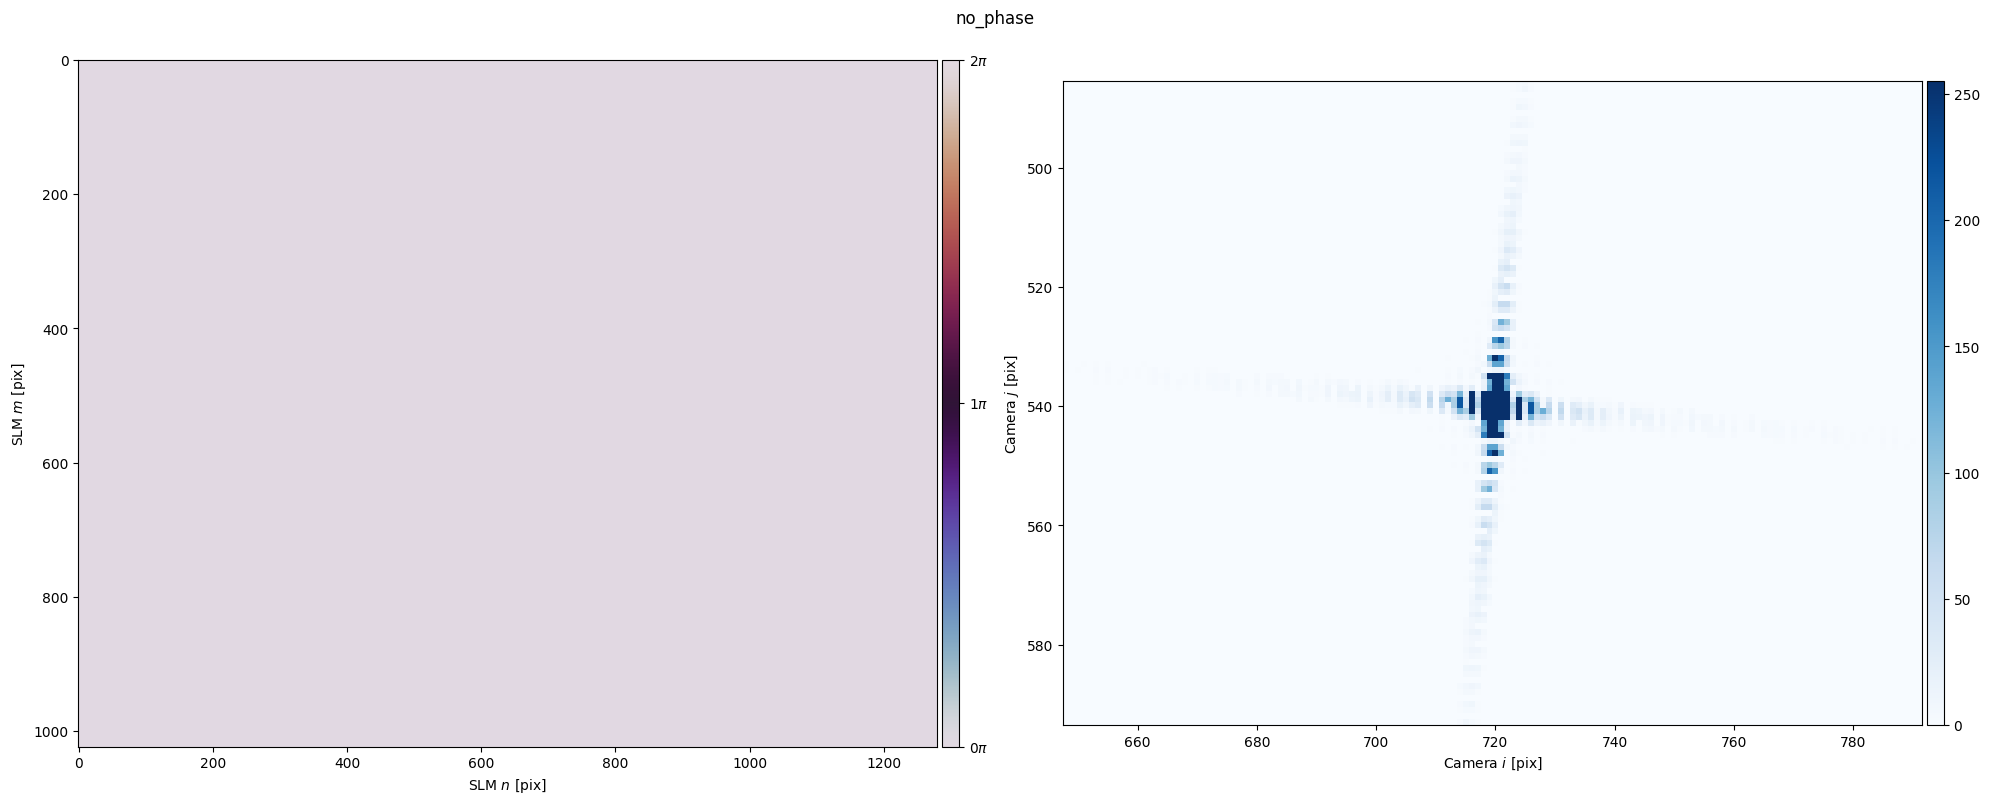

In [4]:

fs.plot(np.zeros(slm.shape), title="no_phase", cam_limits=.1)

<Axes: title={'center': 'Image'}, xlabel='Camera $i$ [pix]', ylabel='Camera $j$ [pix]'>

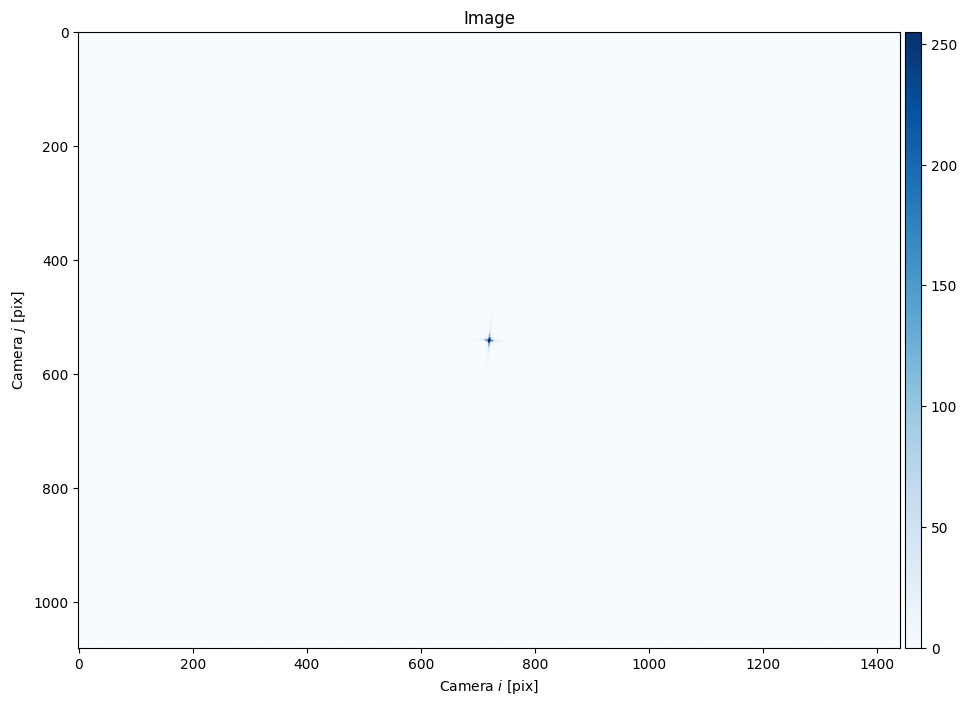

In [5]:
cam.plot()

In [6]:
from slmsuite.holography.algorithms import Hologram
target_size = (32, 32)
target = np.zeros(target_size)
target[9, 24] = 1

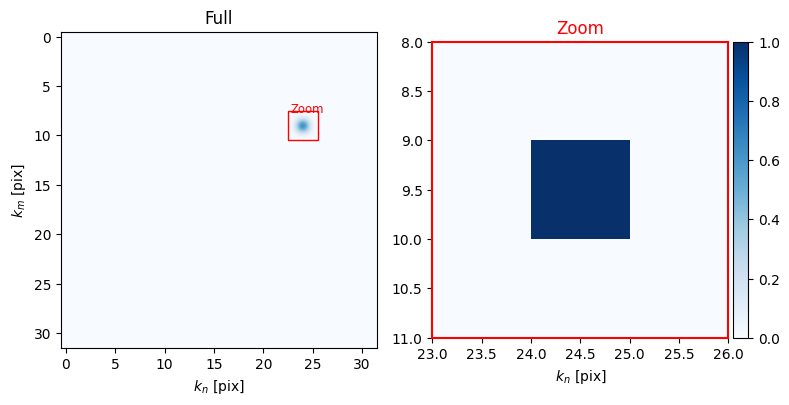

In [7]:
slm_size = target_size
hologram = Hologram(target, slm_shape=slm_shape)
hologram.cameraslm = fs
zoombox = hologram.plot_farfield(source=hologram.target, cbar=True)

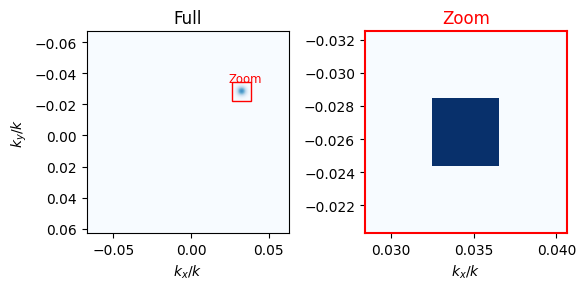

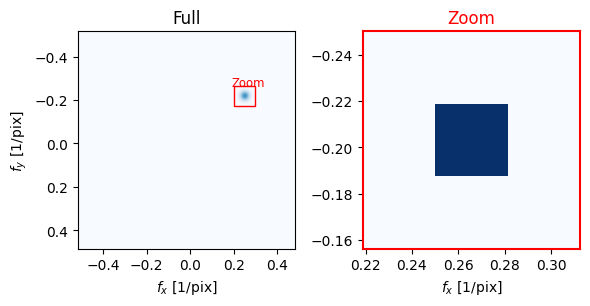

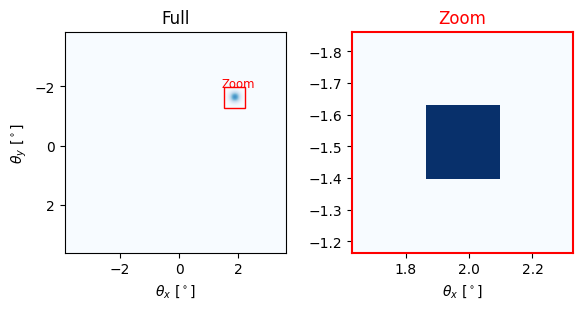

In [8]:
# Not all inclusive, but try out a few units
for units in ["kxy", "freq", "deg"]:
    hologram.plot_farfield(source=hologram.target, units=units, figsize=(6,3))

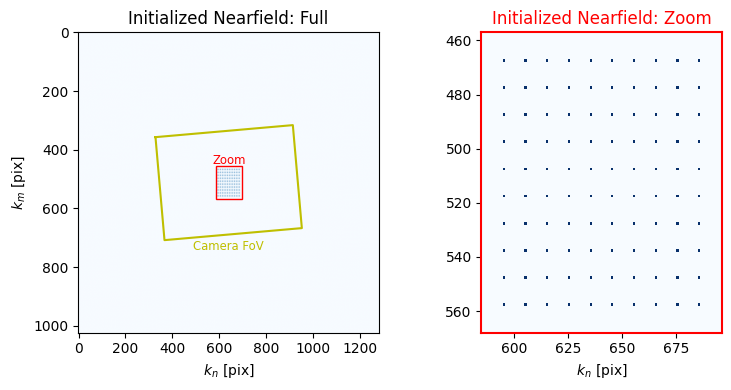

In [9]:
from slmsuite.holography.algorithms import SpotHologram

# Move to a larger grid size
slm_size = slm_shape

# Instead of picking a few points, make a rectangular grid in the knm basis
array_holo = SpotHologram.make_rectangular_array(
    slm_size,
    array_shape=(10,10),
    array_pitch=(10,10),
    basis='knm',
    cameraslm = fs
)
zoom = array_holo.plot_farfield(source=array_holo.target, title='Initialized Nearfield')

In [10]:
# Example callback function: plot the FF every 10 iterations
def plot_ff(holo):
    if holo.iter % 10 == 0:
        holo.plot_farfield(limits=zoom, title='Iteration %d'%array_holo.iter)

# Now we'll run the computation using 21 iterations of GS.
array_holo.optimize(method="GS", maxiter=21,feedback="experimental_spot",
                    stat_groups=['experimental_spot'], verbose=False)

<Axes: title={'center': 'Image'}, xlabel='Camera $i$ [pix]', ylabel='Camera $j$ [pix]'>

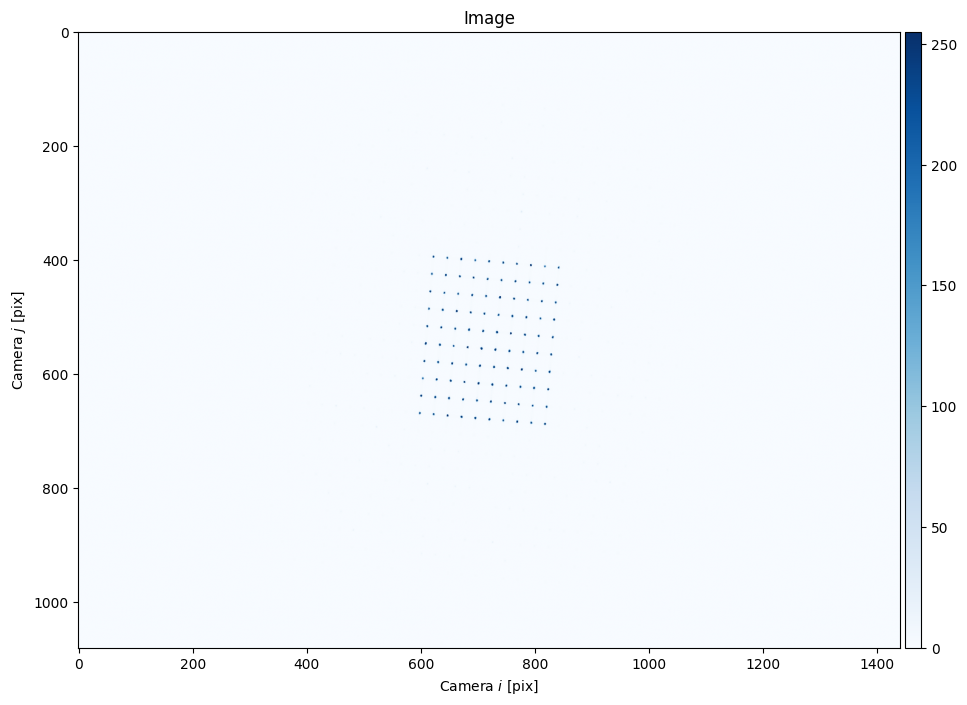

In [11]:
fs.cam.plot()

In [12]:
from slmsuite.holography.toolbox import format_vectors

In [13]:
center = format_vectors((1000, 500))
res = (320, 320)
((i0, i1), (i2, i3)) = limits = (
    (int(center[0] - res[0]/2), int(center[0] + res[0]/2)),
    (int(center[1] - res[1]/2), int(center[1] + res[1]/2))
)

In [14]:
center

array([[1000],
       [ 500]])

## Structured Light

In [3]:
from slmsuite.hardware.cameraslms import FourierSLM

try:
    # Try to load physical hardware.
    from slmsuite.hardware.slms.santec import Santec
    from slmsuite.hardware.cameras.alliedvision import AlliedVision

    # Load the hardware.
    slm = Santec(slm_number=1, display_number=2, wav_um=.633, settle_time_s=.5); print()
    cam = AlliedVision(serial="02C5V", verbose=True, fliplr=True)

    # Load the composite CameraSLM.
    fs = FourierSLM(cam, slm)
    fs.read_calibration("wavefront_superpixel")
    fs.wavefront_calibration_superpixel_process(r2_threshold=.5, plot=True);
except Exception as e:
    print(f"Loading physical hardware failed; loading virtual hardware. Error:\n{str(e)}")
    # Fallback to virtual hardware.
    from slmsuite.hardware.slms.simulated import SimulatedSLM
    from slmsuite.hardware.cameras.simulated import SimulatedCamera

    # Make the SLM and camera.
    slm = SimulatedSLM((1600, 1200), pitch_um=(8,8))
    slm.set_source_analytic(sim=True)               # Program the virtual source.
    slm.set_source_analytic()                       # Don't bother with wavefront calibration, instead just set it to the same source.

    cam = SimulatedCamera(slm, (1440, 1100), pitch_um=(4,4), gain=200)

    # Tie the camera and SLM together with an analytic calibration.
    fs = FourierSLM(cam, slm)
    M, b = fs.fourier_calibration_build(
        f_eff=80000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
        theta=5 * np.pi / 180,
    )
    cam.set_affine(M, b)
    fs.fourier_calibrate_analytic(M, b)

Loading physical hardware failed; loading virtual hardware. Error:
Santec DLLs not installed. Install these to use Santec SLMs.  Dynamically linked libraries from Santec (usually provided via USB) must be present in the runtime directory:
  - SLMFunc.dll
  - FTD3XX.dll
  Check that these files are present and are error-free.


In [4]:
from slmsuite.holography import toolbox
from slmsuite.holography.toolbox import phase

x_list = np.arange(2000)
y_list = np.arange(1000)
x_grid, y_grid = np.meshgrid(x_list, y_list)

blaze_phase = phase.blaze(
    grid=(x_grid, y_grid),          # Coordinates of our SLM pixels.
    vector=(.002, .002)             # Angle vector (in normalized units) to blaze towards.
)

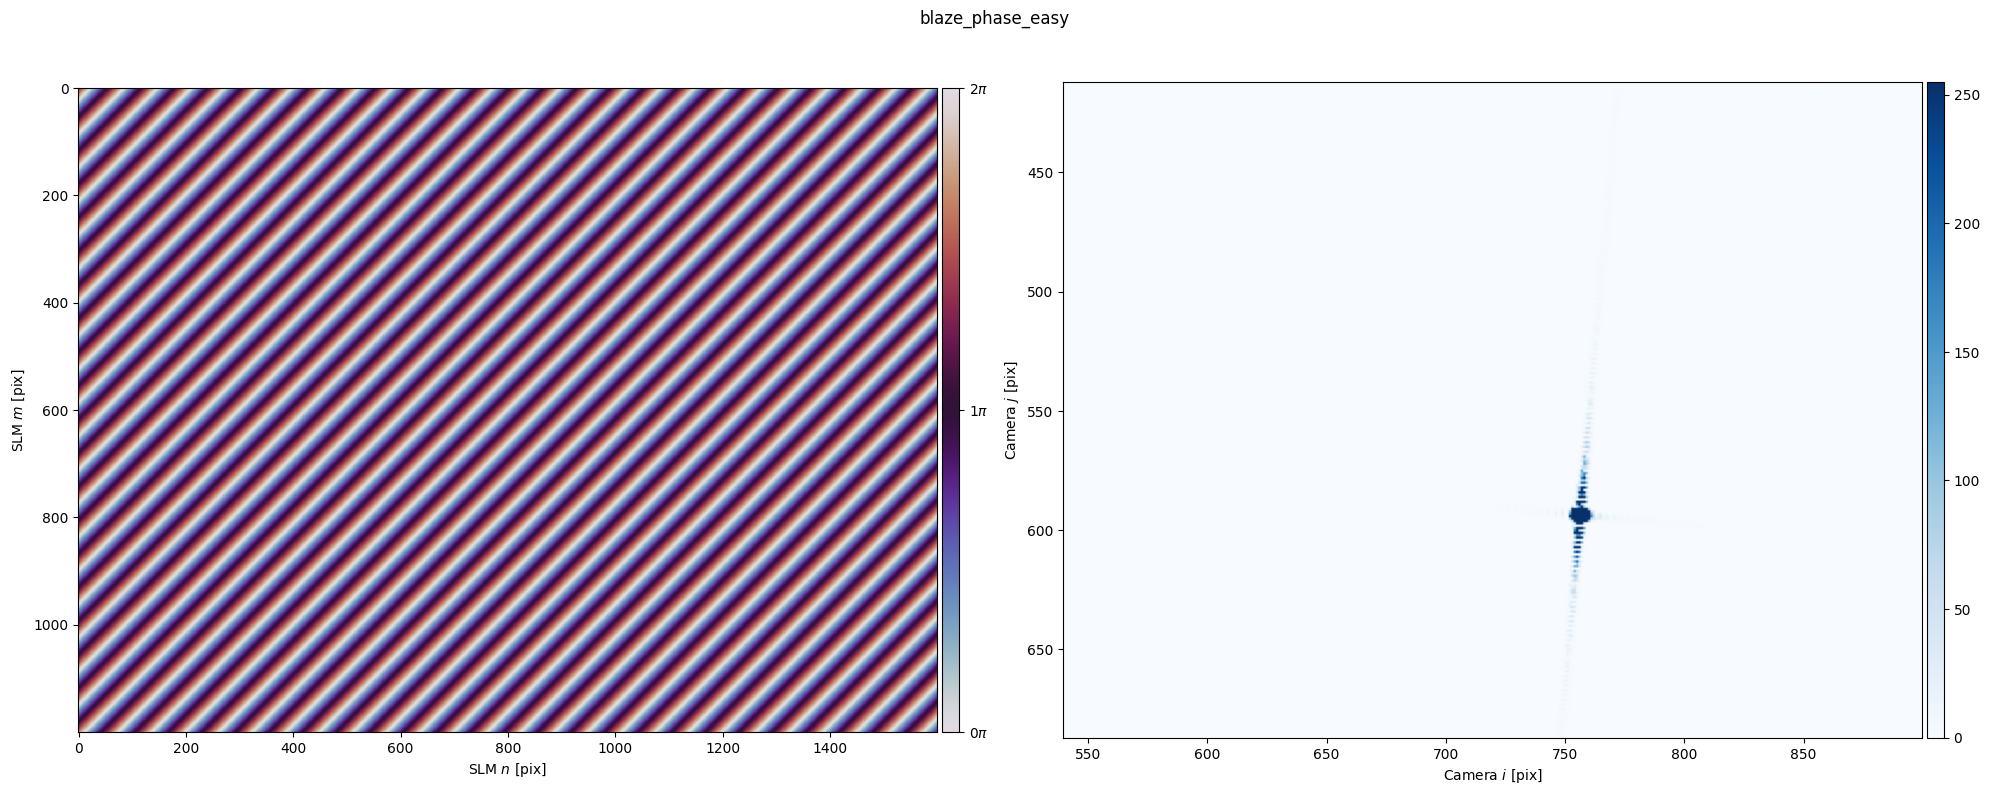

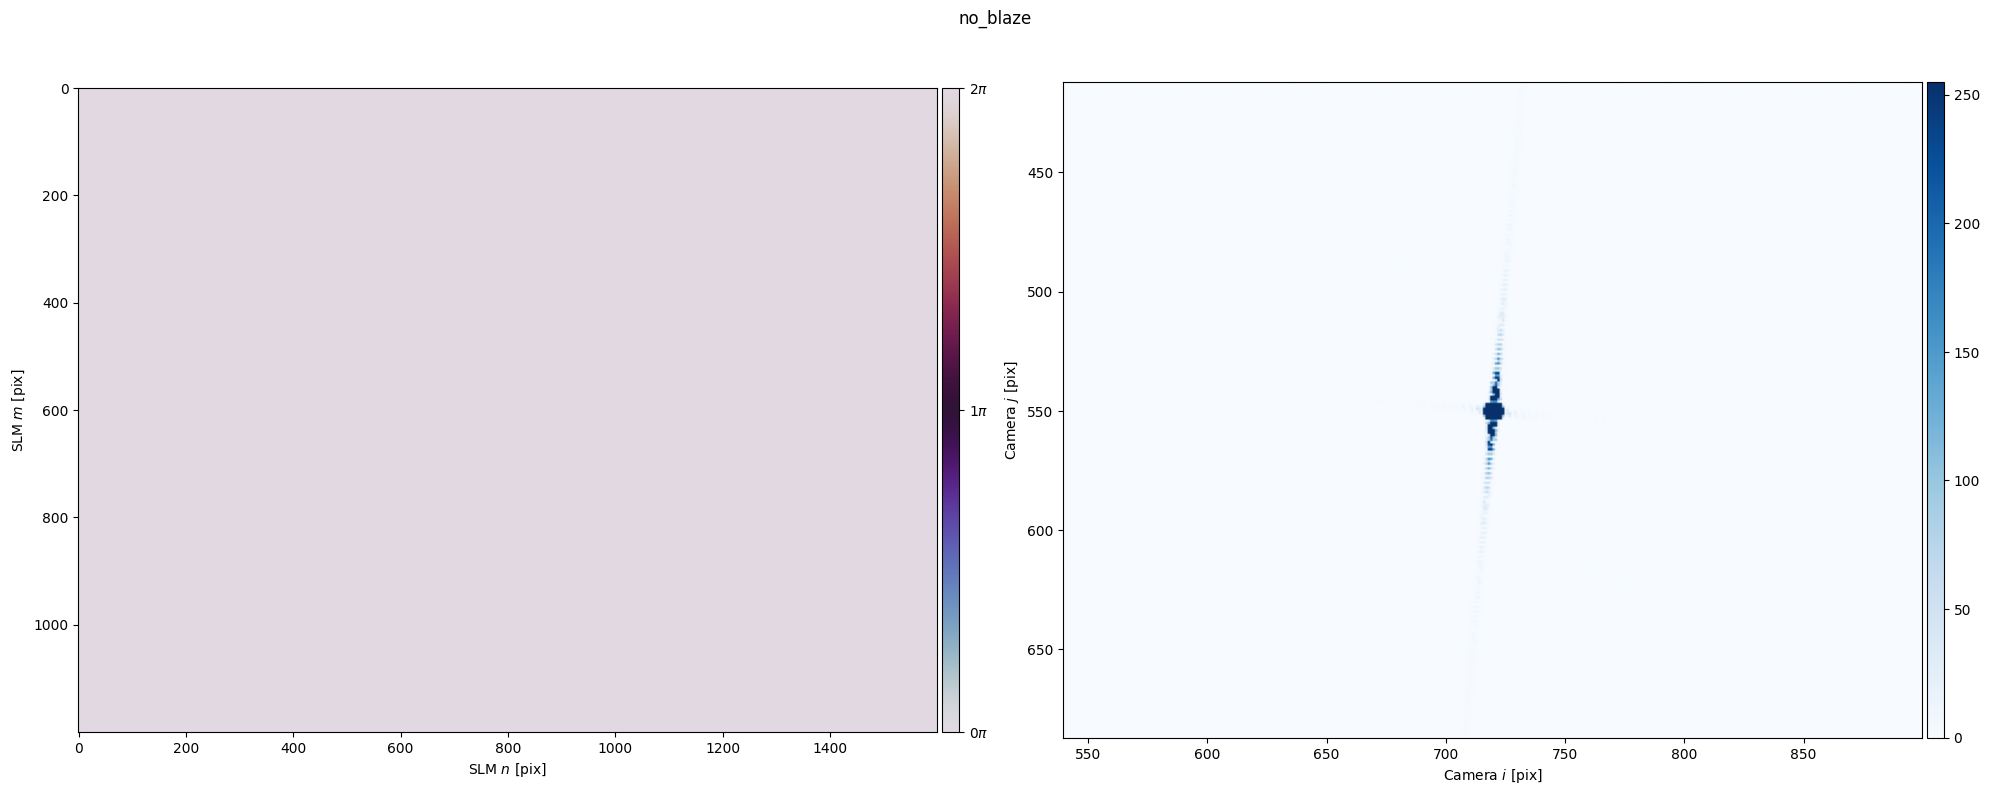

In [6]:
blaze_phase_easy = phase.blaze(
    grid=slm,                       # Coordinates of our SLM pixels, inherited from the SLM.
    vector=(.002, .002)             # Again, angle vector (in normalized units) to blaze towards.
)

# Plotting.
fs.plot(blaze_phase_easy, title="blaze_phase_easy", cam_limits=.25);
plt.show()

no_blaze = phase.blaze(grid=slm, vector=(0,0))
fs.plot(no_blaze, title="no_blaze", cam_limits=.25);

In [5]:
blaze_phase_easy

array([[-1406.42819916, -1405.42288951, -1404.41757986, ...,
          199.05131053,   200.05662018,   201.06192983],
       [-1405.42288951, -1404.41757986, -1403.41227021, ...,
          200.05662018,   201.06192983,   202.06723948],
       [-1404.41757986, -1403.41227021, -1402.40696056, ...,
          201.06192983,   202.06723948,   203.07254913],
       ...,
       [ -203.07254913,  -202.06723948,  -201.06192983, ...,
         1402.40696056,  1403.41227021,  1404.41757986],
       [ -202.06723948,  -201.06192983,  -200.05662018, ...,
         1403.41227021,  1404.41757986,  1405.42288951],
       [ -201.06192983,  -200.05662018,  -199.05131053, ...,
         1404.41757986,  1405.42288951,  1406.42819916]],
      shape=(1200, 1600))

In [6]:
slm.get_source_center()

array([800., 600.])

In [7]:
ro = 208**2
arr = np.array([[np.pi if ((i-slm.get_source_center()[1])**2 + (j-slm.get_source_center()[0])**2) <= ro else 0 for j in range(1600)] for i in range(1200)])

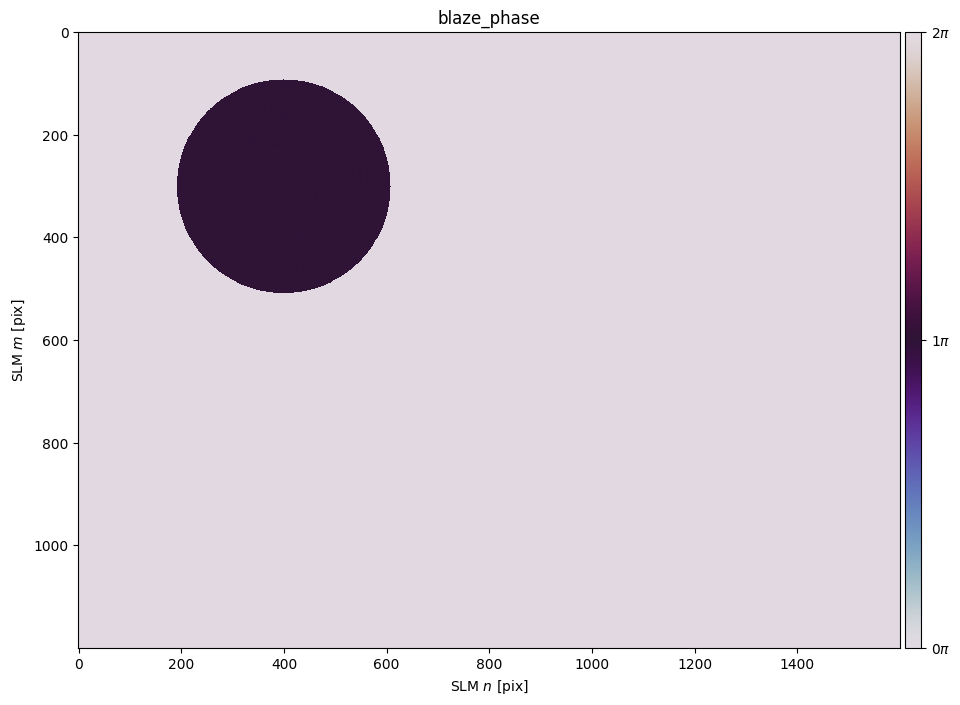

In [8]:
arr_fft = np.fft.fft2(arr)

# Define how much you want to shift the zeroth order
shift_x = 400  # Example shift in x direction (pixels)
shift_y = 300  # Example shift in y direction (pixels)

# Apply a phase shift directly in the Fourier domain to move the zeroth order
rows, cols = arr.shape
x = np.fft.fftfreq(cols)  # Frequency bins in x direction
y = np.fft.fftfreq(rows)  # Frequency bins in y direction
X, Y = np.meshgrid(x, y)  # Generate meshgrid for frequency shift

# Create a phase shift to apply to the Fourier domain
# The phase shift is a linear ramp in frequency space
phase_shift = np.exp(1j * 2 * np.pi * (X * shift_x + Y * shift_y))

# Apply the phase shift to the Fourier-transformed mask
arr_fft_shifted = arr_fft * phase_shift

# Inverse FFT to get the shifted mask back in the spatial domain
arr_shifted = np.fft.ifft2(arr_fft_shifted)

# Take the real part of the result (since the mask should be real)
arr_shifted = np.real(arr_shifted)

fs.slm.plot(arr_shifted, title="blaze_phase");


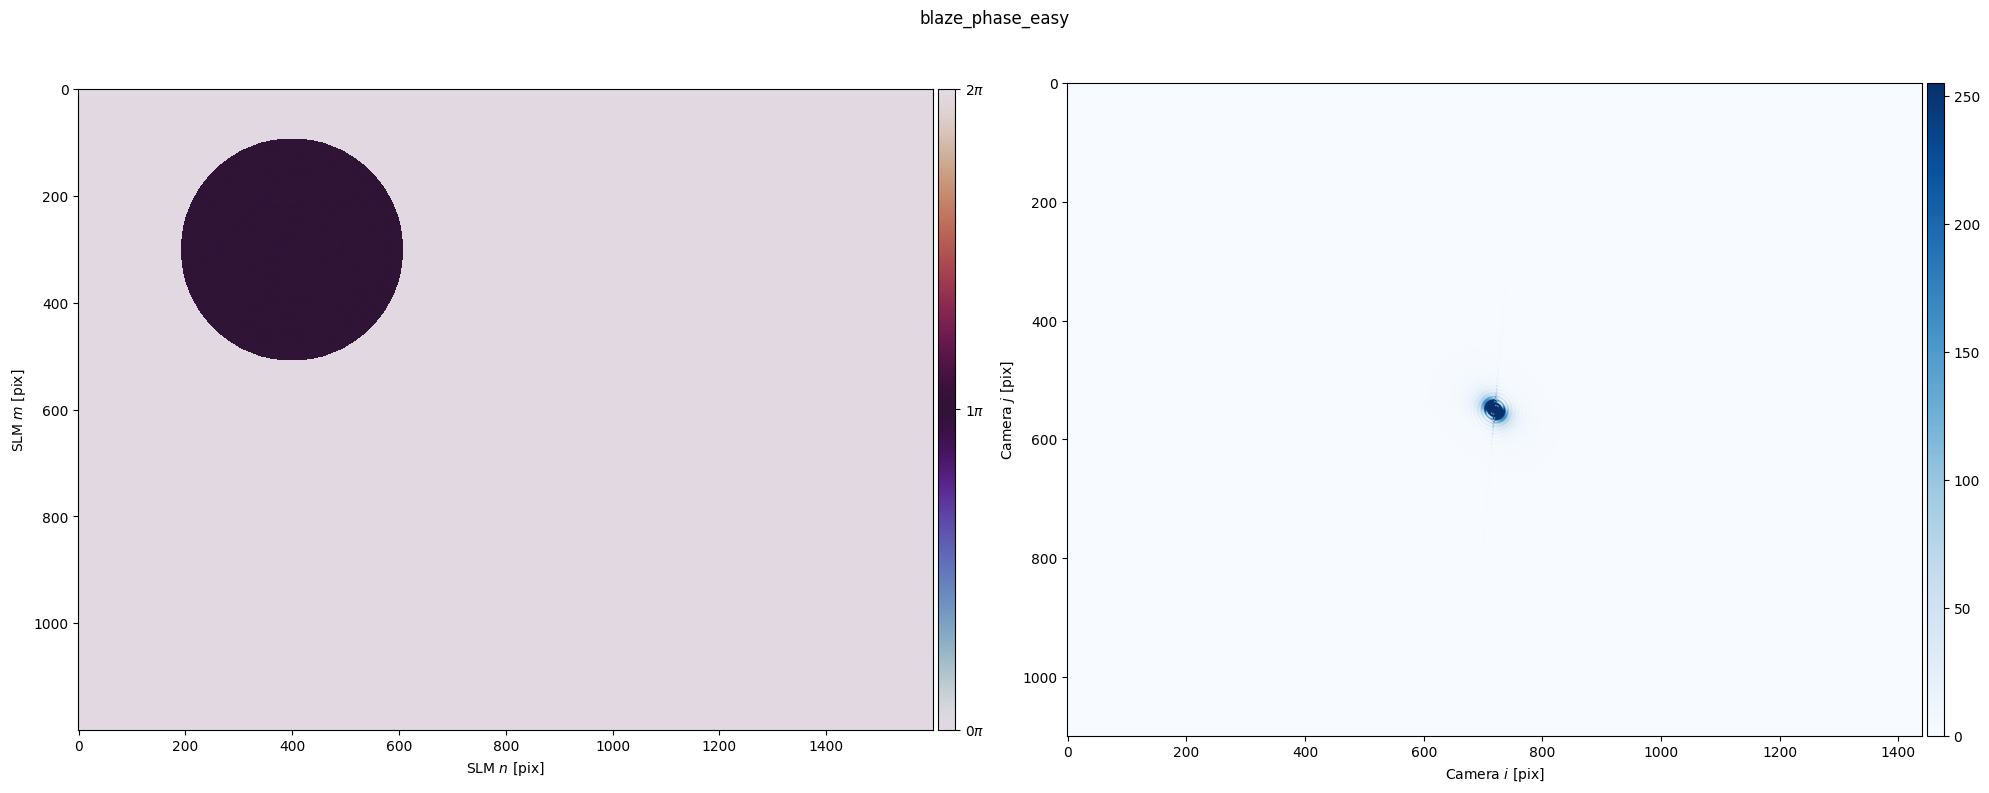

In [9]:
#ro = 80k
fs.plot(arr_shifted, title="blaze_phase_easy", cam_limits=1);
plt.show()

In [157]:
ro = 246**2
arr = np.array([[np.pi if ((i-slm.get_source_center()[1])**2 + (j-slm.get_source_center()[0])**2) <= ro else 0 for j in range(1600)] for i in range(1200)])

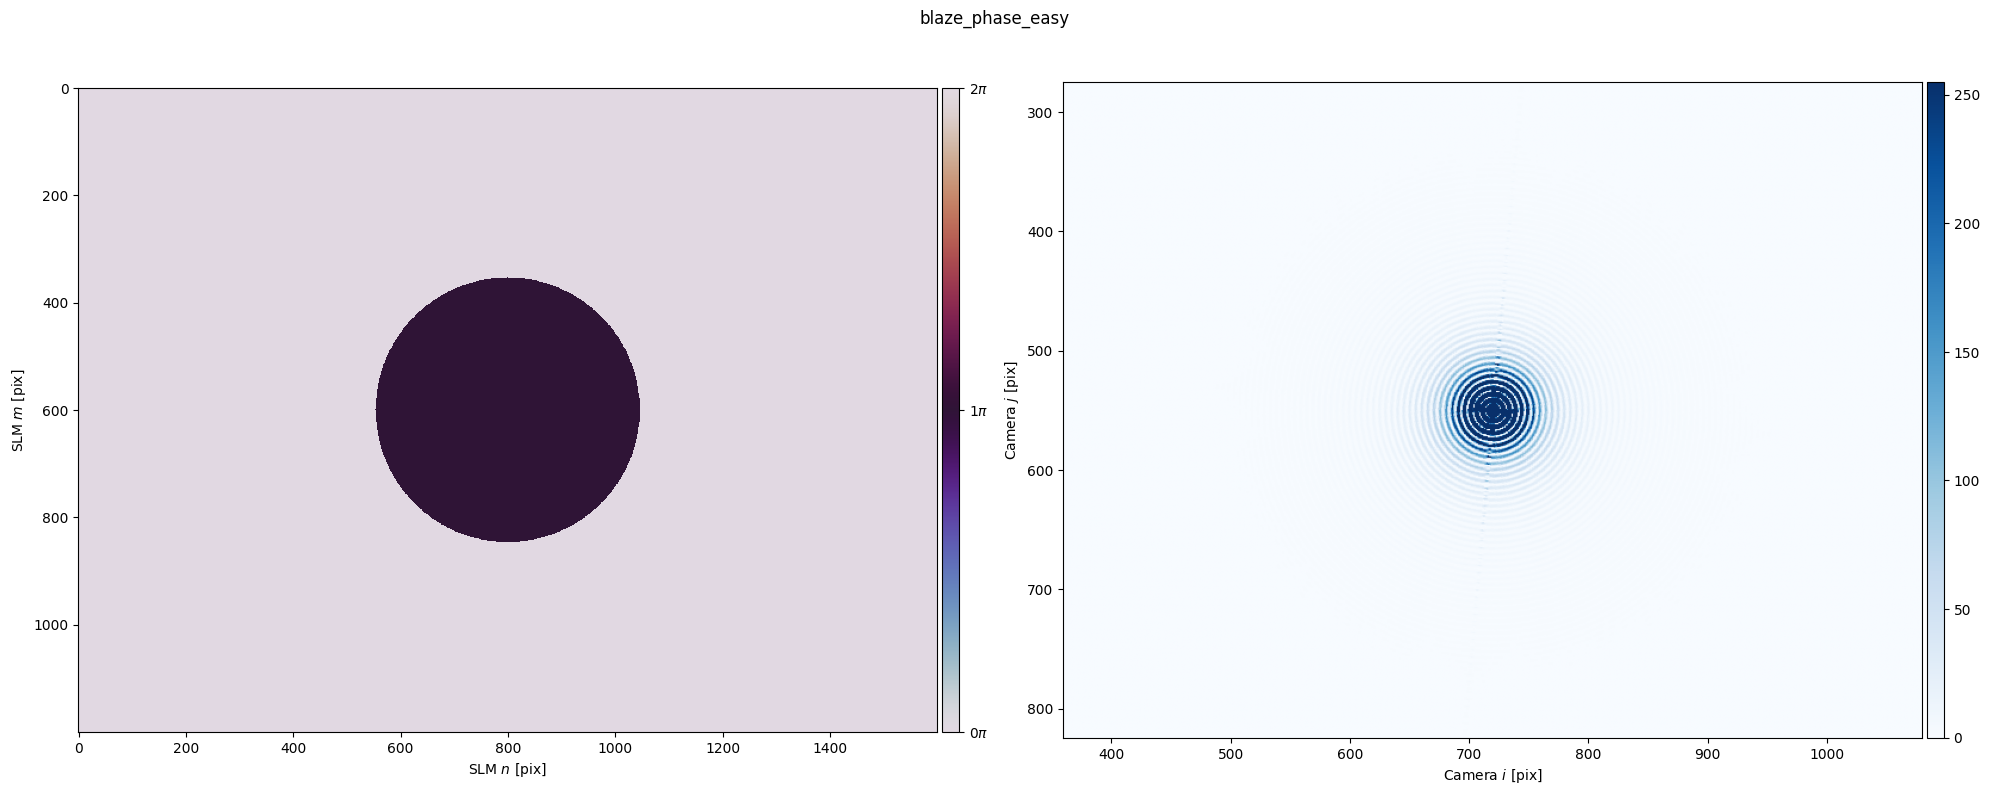

In [159]:
#ro = 10k
fs.plot(arr, title="blaze_phase_easy", cam_limits=0.5);
plt.show()

In [121]:
xm = 10000
ym = 800
wl = 1.040
f = 80000*wl
zm = f
deltam = np.array([[(((i-slm.get_source_center()[1])**2 + (j-slm.get_source_center()[0])**2)*zm/f + ((i-slm.get_source_center()[1])*xm + (j-slm.get_source_center()[0])*ym)*2)*np.pi/(wl*f) for j in range(1600)] for i in range(1200)])

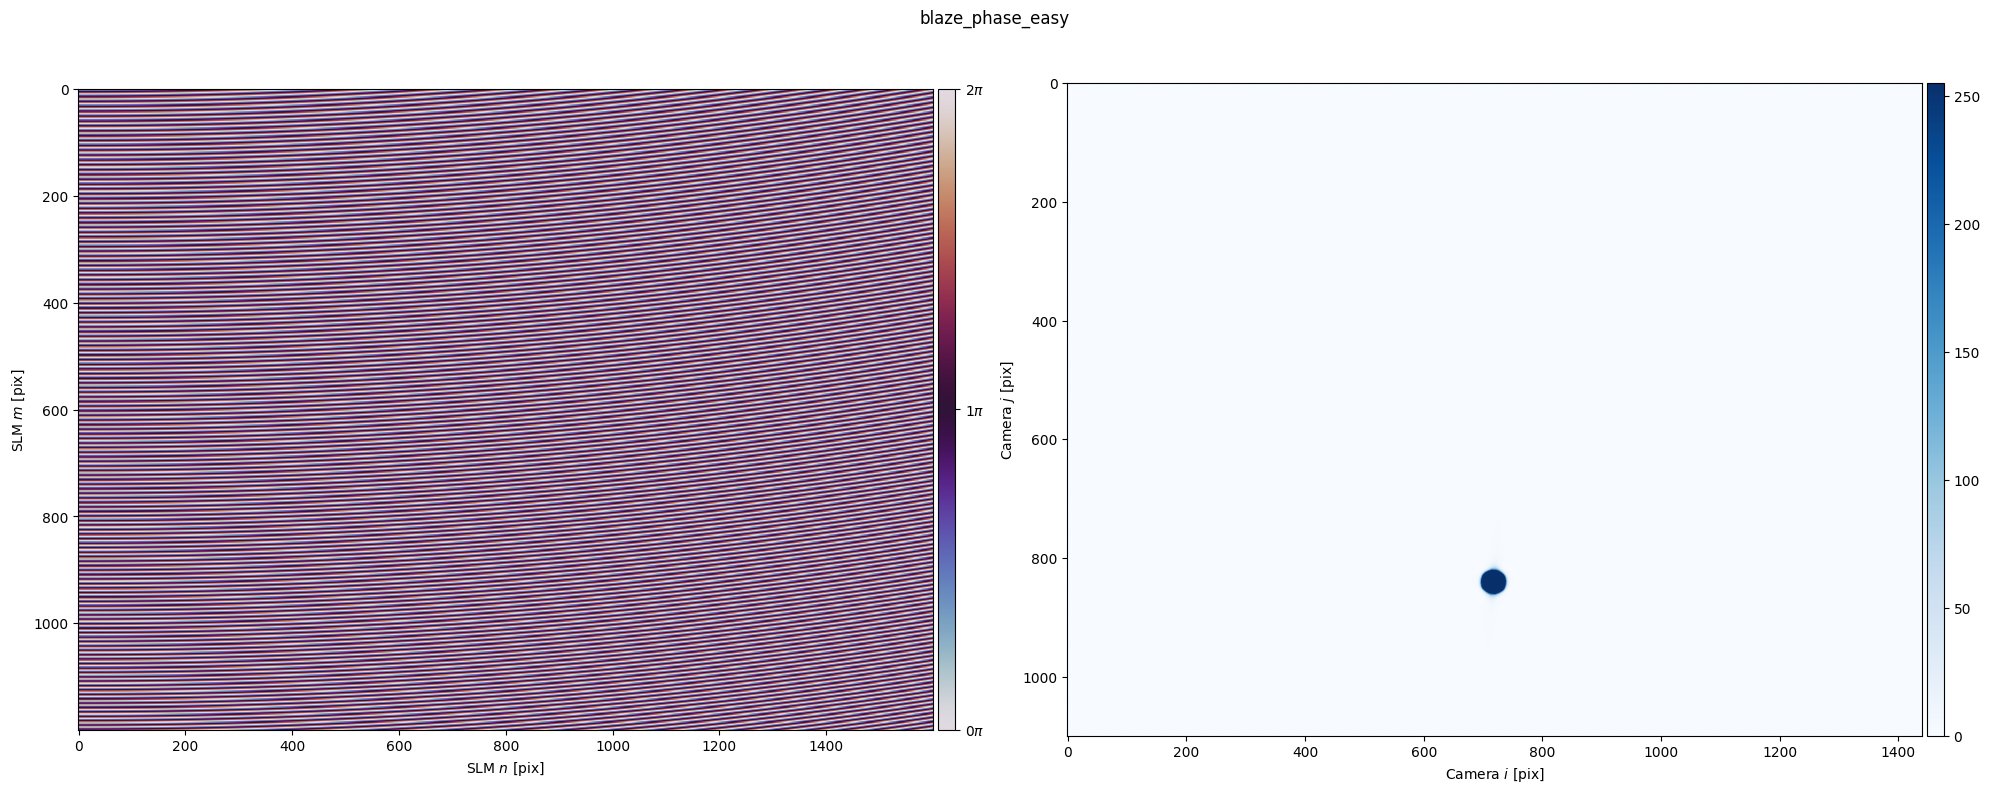

In [122]:
fs.plot(deltam, title="blaze_phase_easy", cam_limits=1);
plt.show()

In [154]:
w0 = 1924/7.5
a = 1024/2
w0*(-np.log(0.5*(1+np.e**(-a**2/w0**2))))**0.5

np.float64(210.71616857887756)

In [156]:
w0 = 2371/8
a = 1200/2
w0*(-np.log(0.5*(1+np.e**(-a**2/w0**2))))**0.5

np.float64(243.80064077429446)

In [10]:
slm.get_source_radius()

np.float64(2371.5320206360925)

In [51]:
# lamda = 1.064
# f = 0.6e6
lamda = 0.633
f = 80000*lamda
# a0 = 3152
a0 = slm.get_source_radius()
Arel =1
w1 = 1.32
w2 = 0.69

def Gff(A,w,r):
    return (A)*(np.e**(-(r**2)/(w**2)))

def G(A,w,r):
    a = (2*np.pi/(lamda*f))
    return (w)*(A/2)*(np.e**((-1/4)*(a**2)*(w**2)*(r**2)))
def bb_phase_2(r):
    K = (G(1,w1,0) - G(Arel,w2,0))
    # return np.arccos(((G(1,w1,r) - G(Arel,w2,r))/(np.e**(-r**2/a0**2)))/K)
    return np.arccos((K*(np.e**(-r**2/a0**2)))/(G(1,w1,r) - G(Arel,w2,r)))


In [52]:
r = 1
Gff(1,w1,r) - Gff(Arel,w2,r)

0.4409047704018377

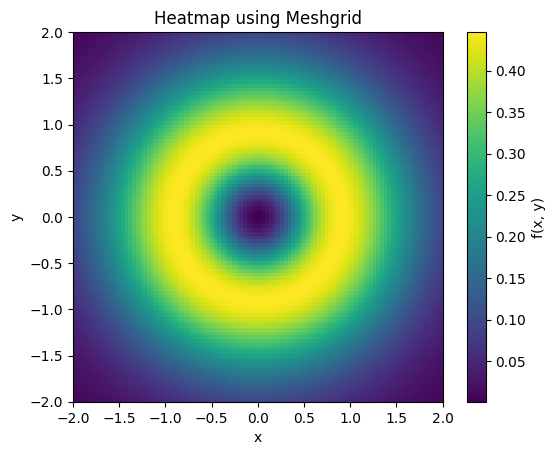

In [53]:
l = 2
x = np.linspace(-l,l,100)
y = np.linspace(-l,l,100)
X, Y = np.meshgrid(x, y)
r = (X**2 + Y**2)**0.5
# r = np.linspace(0,10,100)
I = Gff(1,w1,r) - Gff(Arel,w2,r)
plt.imshow(I, extent=[x.min(), x.max(), y.min(), y.max()], origin='lower', cmap='viridis')
plt.colorbar(label='f(x, y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Heatmap using Meshgrid')
plt.show()

In [54]:
(G(1,w1,a0) - G(Arel,w2,a0))/(G(1,w1,0) - G(Arel,w2,0))

np.float64(0.8395899659149241)

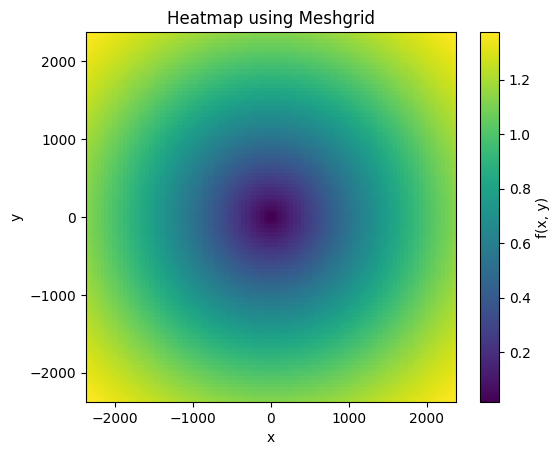

In [55]:
l = 1e-6
x = np.linspace(-a0,a0,100)
y = np.linspace(-a0,a0,100)
X, Y = np.meshgrid(x, y)
r = (X**2 + Y**2)**0.5

I = bb_phase_2(r)
plt.imshow(I, extent=[x.min(), x.max(), y.min(), y.max()], origin='lower', cmap='viridis')
plt.colorbar(label='f(x, y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Heatmap using Meshgrid')
plt.show()

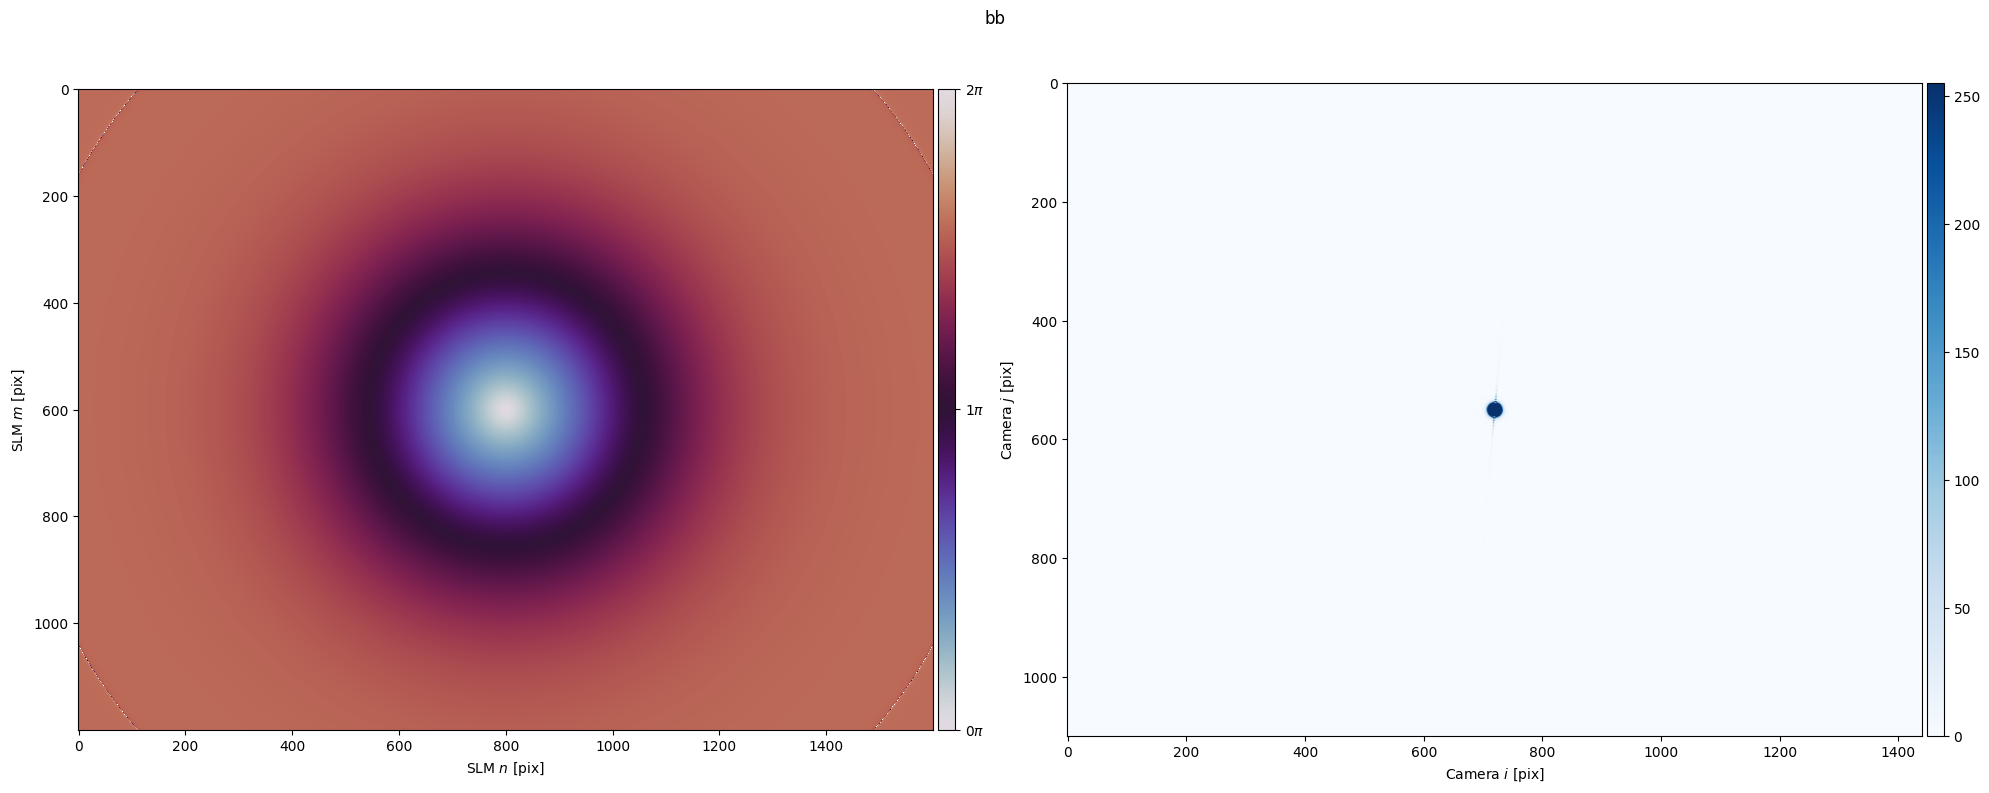

In [56]:
pm = np.pi*np.array([[bb_phase_2((((i-slm.get_source_center()[1])*fs.slm.pitch_um[0])**2 + ((j-slm.get_source_center()[0])*fs.slm.pitch_um[0])**2)**0.5) for j in range(1600)] for i in range(1200)])

fs.plot(pm, title="bb", cam_limits=1);
plt.show()

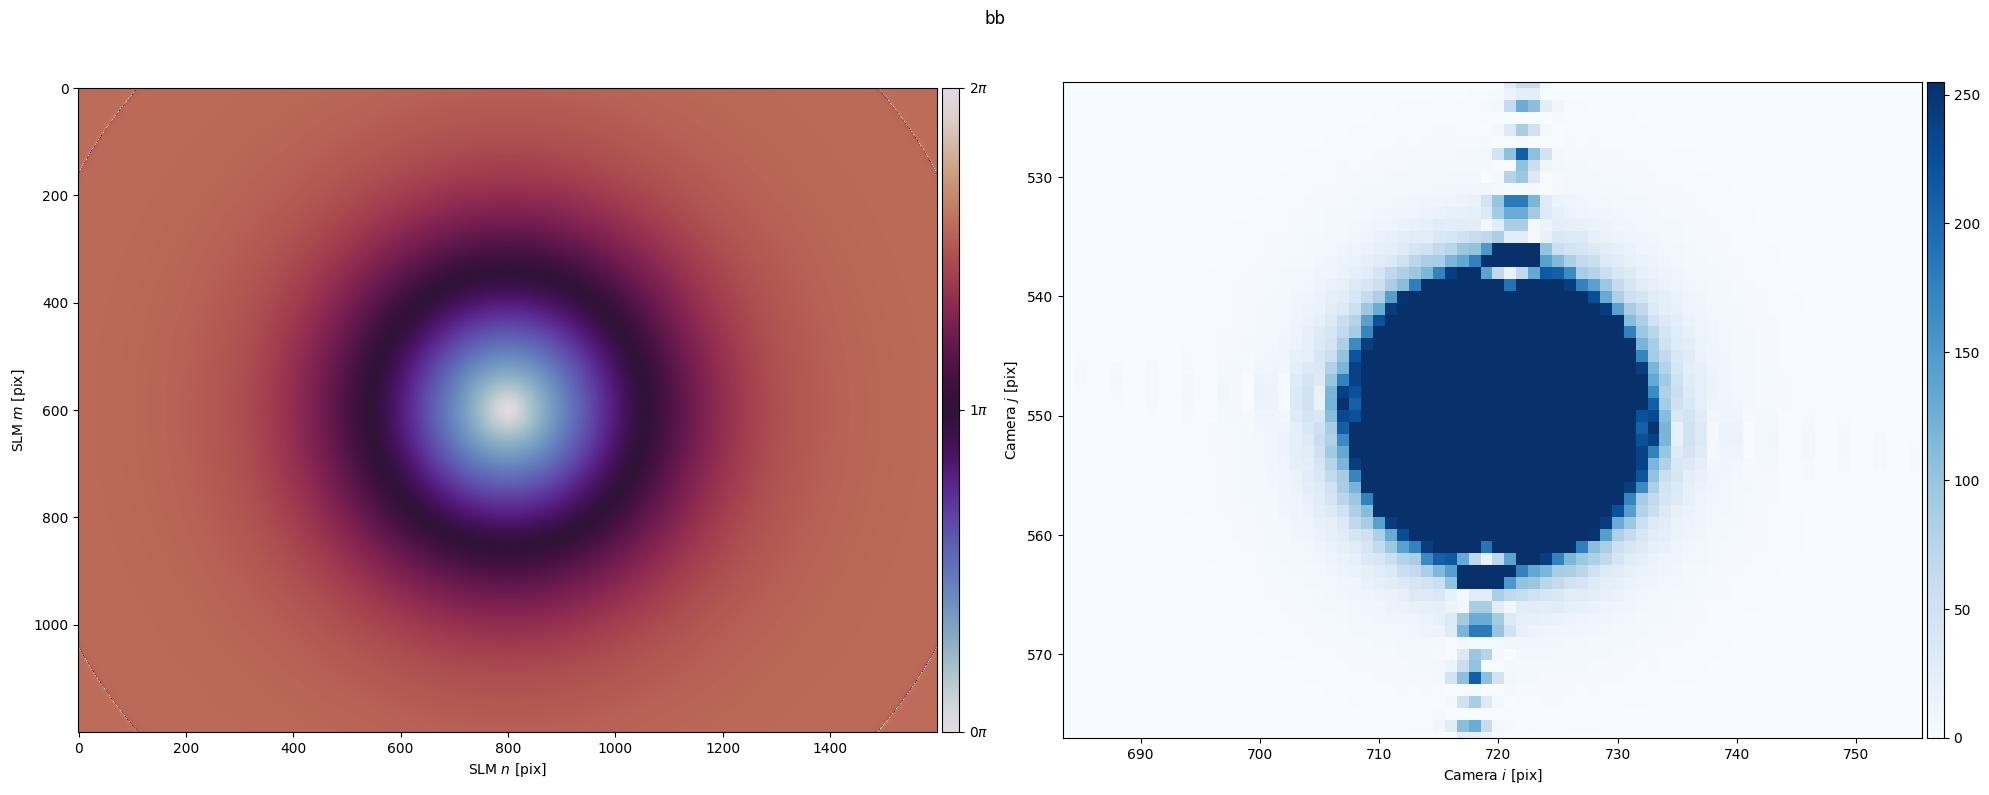

In [57]:
fs.plot(pm, title="bb", cam_limits=0.05);
plt.show()

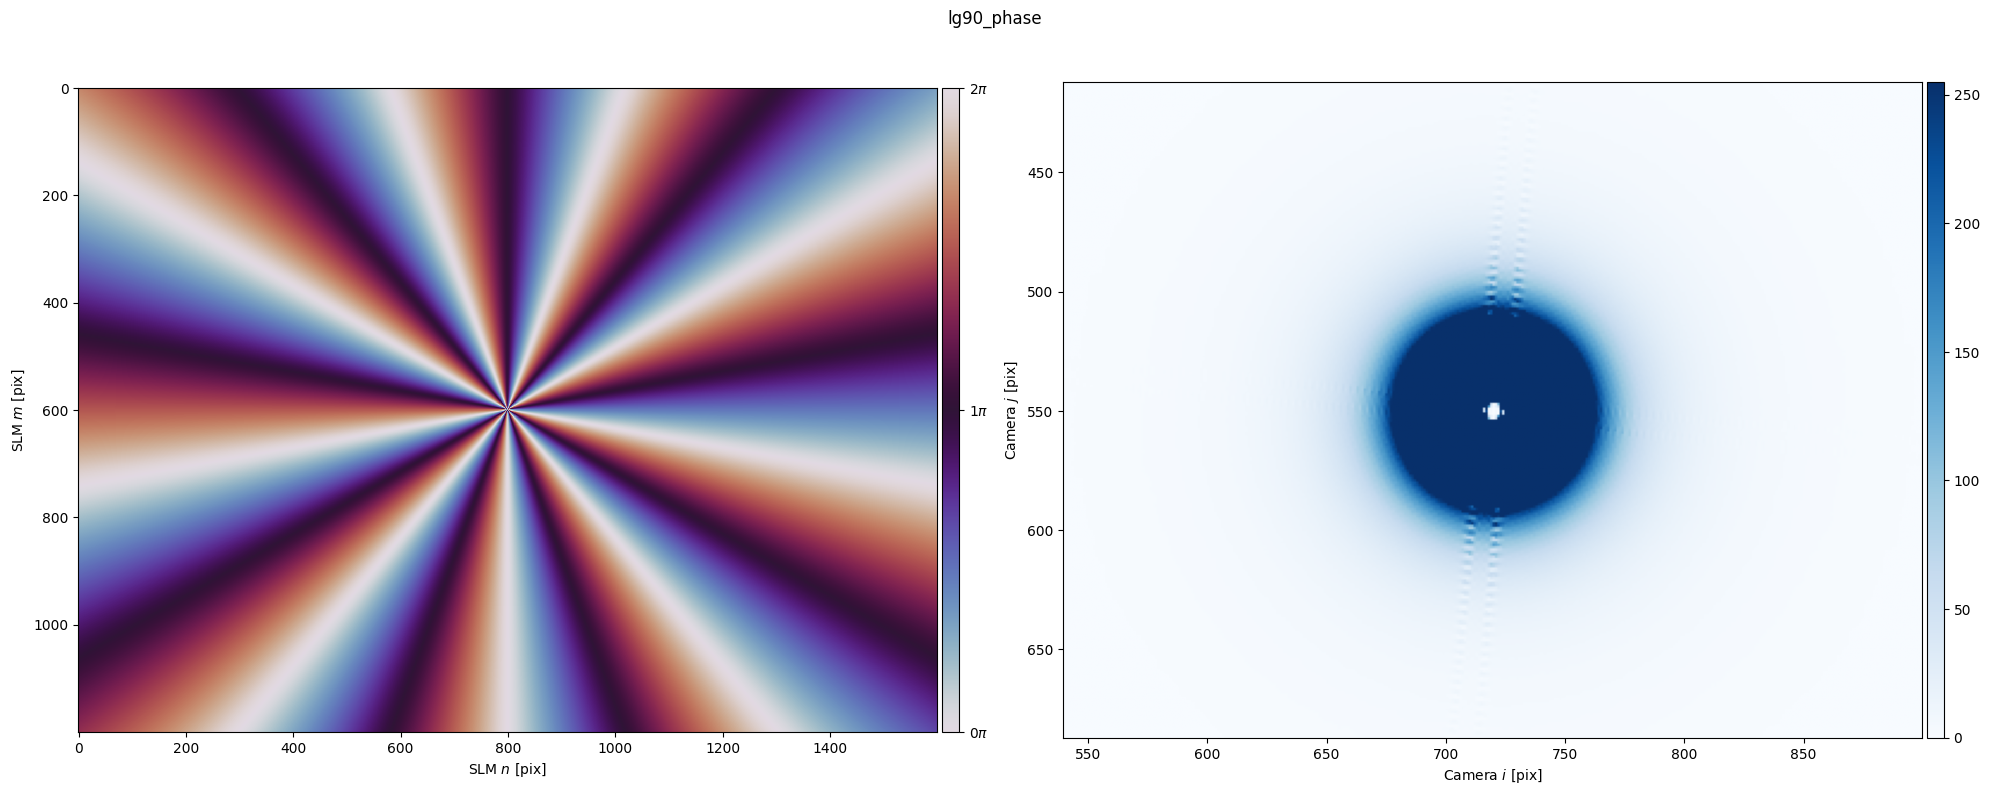

In [19]:
lg90_phase = phase.laguerre_gaussian(
    slm,
    l=9,                                        # A larger azimuthal wavenumber
    p=0
)

fs.plot(lg90_phase, title="lg90_phase", cam_limits=.25);

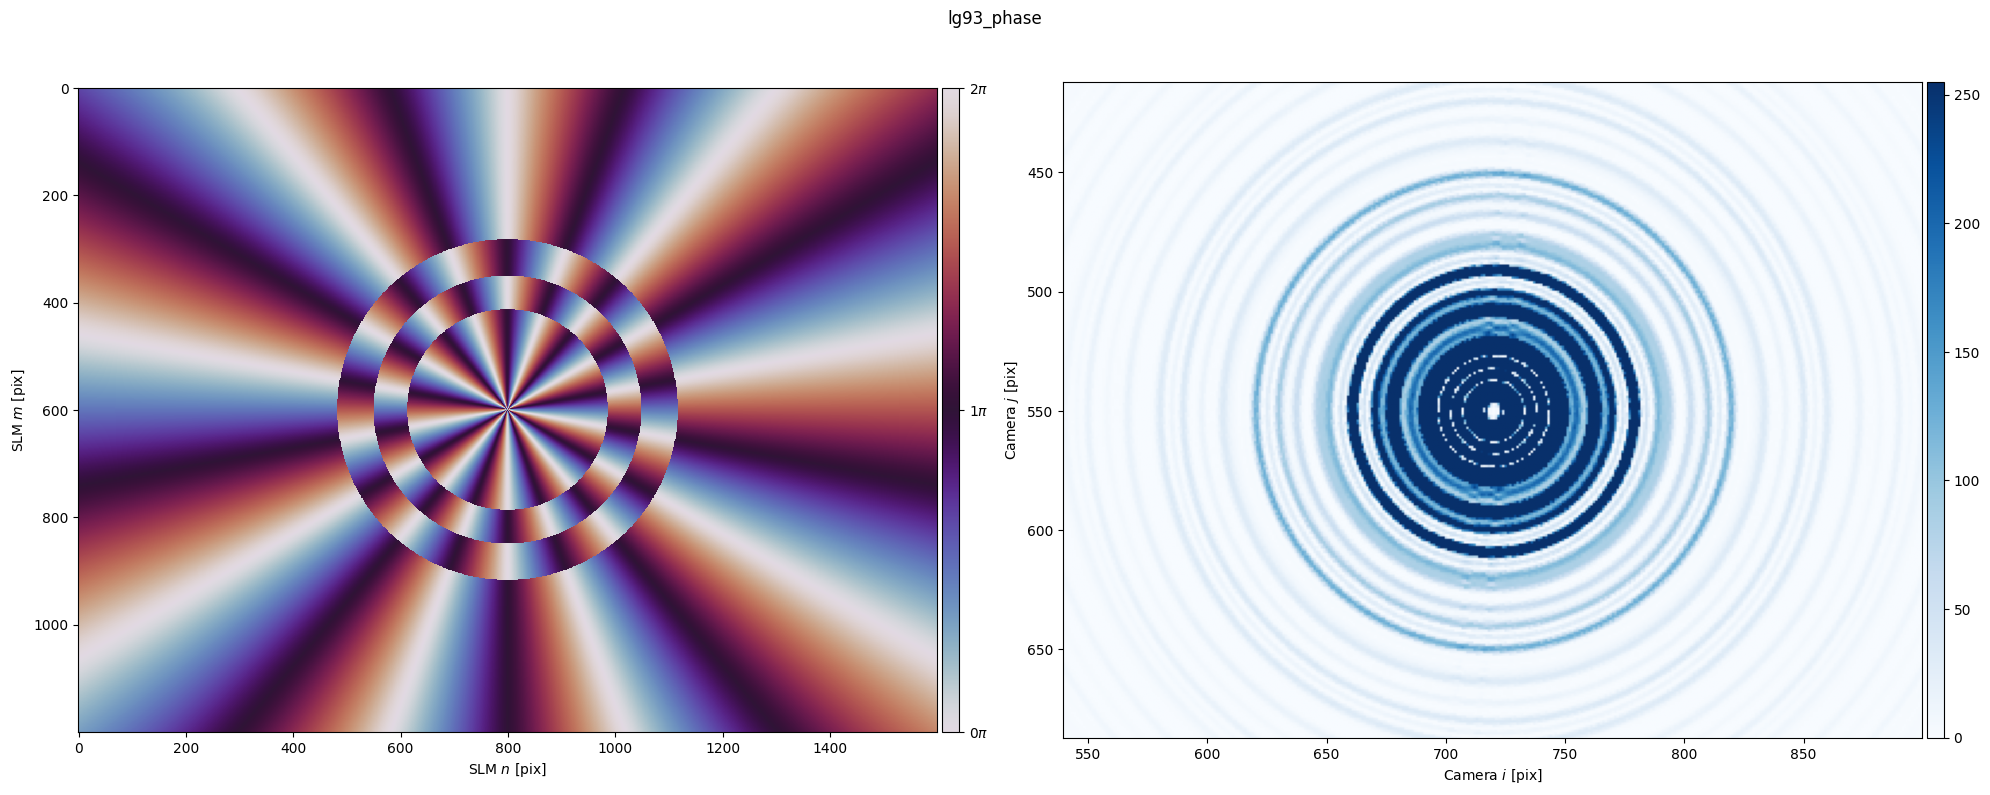

In [20]:
lg93_phase = phase.laguerre_gaussian(
    slm,
    l=9,
    p=3                                         # Nonzero radial wavenumber
)

fs.plot(lg93_phase, title="lg93_phase", cam_limits=.25);